# 51 Fusion Fitting

**Purpose:** Compare every branch alone with the learned fusion head out-of-fold on train + val, fit the fusion head on all of train + val, and save it.

**Inputs:** The branch-output cache from notebook 50 (`<data dir>/cache/fusion/`).

**Outputs:** `models/fusion/fusion_head.npz` and `models/fusion/fusion_info.json`; the chosen C and temperature for each method.

**Splits used:** train + val only (out-of-fold, grouped by video); test: not used (scored once in notebook 52).

In [8]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from woofdata.path import data_path, load_data_dir_from_env_file
from woofdecoder.config import REPO_ROOT
from woofdecoder.constants import FEATURE_NAMES
from woofdecoder.fusion import FusionModel
from woofdecoder.taxonomy import CATEGORIES
from wooftrainer.audio_trainer.audio_heads import balanced_weights
from wooftrainer.fusion_trainer.branch_outputs import load_branch_outputs
from wooftrainer.fusion_trainer.train import compare_methods, fit_fusion, video_weights
from wooftrainer.plots import plot_confusion_matrix
from wooftrainer.settings import (
    FUSION_BOOTSTRAP_REPEATS,
    FUSION_BOOTSTRAP_SEED,
    FUSION_CACHE_DIR,
    FUSION_CACHE_INFO_FILENAME,
    FUSION_MODEL_DIR,
    SCORE_PROB_FLOOR,
)

pd.set_option("display.width", 200)

In [9]:
load_data_dir_from_env_file()

FUSION_DIR = REPO_ROOT / FUSION_MODEL_DIR
FUSION_INFO_PATH = (
    data_path(FUSION_CACHE_DIR) / FUSION_CACHE_INFO_FILENAME
)  # written by notebook 50

## Compare methods

Out-of-fold scores on train + val for each branch (raw and learned) and for the fusion head, with the C search per method.

In [10]:
segments, videos = load_branch_outputs()

table, learned, trainval = compare_methods(segments)
print(f"train + val: {len(trainval)} segments, {trainval['video_id'].nunique()} videos\n")
print(table.round(3).to_string(index=False))

train + val: 589 segments, 76 videos

        method  segment_log_loss  segment_macro_f1  video_macro_f1  video_accuracy   C  temperature
     audio raw             1.429             0.475           0.475           0.487 NaN          NaN
      body raw             1.940             0.319           0.308           0.342 NaN          NaN
     scene raw             1.949             0.171           0.155           0.237 NaN          NaN
   average raw             1.398             0.399           0.452           0.461 NaN          NaN
 audio learned             1.310             0.425           0.511           0.526 1.0        1.165
  body learned             1.484             0.333           0.362           0.355 1.0        1.655
 scene learned             1.450             0.291           0.285           0.289 0.1        1.054
fusion learned             1.089             0.556           0.564           0.566 1.0        1.373


- branch_raw = segment → AudioBranch → 5 probabilities → prediction
- branch_learned = segment → AudioBranch → 5 probabilities → small logistic regression → 5 new probabilities → prediction

In [11]:
for name, method in learned.items():
    best = method.c_table.iloc[int(method.c_table["log_loss"].to_numpy().argmin())]
    print(f"\n{name}: chosen C = {method.C}  (lowest log-loss {best['log_loss']:.3f})")
    print(method.c_table.round(3).to_string(index=False))


audio learned: chosen C = 1.0  (lowest log-loss 1.316)
 log_loss  macro_f1       C
    1.651     0.067   0.001
    1.559     0.283   0.010
    1.364     0.421   0.100
    1.316     0.425   1.000
    1.346     0.432  10.000
    1.356     0.451 100.000

body learned: chosen C = 1.0  (lowest log-loss 1.522)
 log_loss  macro_f1       C
    1.659     0.059   0.001
    1.619     0.178   0.010
    1.522     0.290   0.100
    1.522     0.333   1.000
    1.582     0.315  10.000
    1.622     0.316 100.000

scene learned: chosen C = 0.1  (lowest log-loss 1.450)
 log_loss  macro_f1       C
    1.654     0.048   0.001
    1.582     0.224   0.010
    1.450     0.291   0.100
    1.516     0.356   1.000
    1.604     0.349  10.000
    1.621     0.347 100.000

fusion learned: chosen C = 1.0  (lowest log-loss 1.125)
 log_loss  macro_f1       C
    1.634     0.095   0.001
    1.450     0.413   0.010
    1.139     0.504   0.100
    1.125     0.556   1.000
    1.346     0.535  10.000
    1.526     0.535 

## Sample test with paired comparison

Resample whole videos to compare fusion with the learned audio head on segment log-loss.

In [12]:
labels = trainval["category"].to_numpy()
weights = balanced_weights(labels, video_weights(trainval))
true_index = np.array([CATEGORIES.index(label) for label in labels])


def segment_losses(probs):
    return -np.log(np.clip(probs[np.arange(len(probs)), true_index], SCORE_PROB_FLOOR, 1.0))


fusion_loss = segment_losses(learned["fusion learned"].oof_probs)
audio_loss = segment_losses(learned["audio learned"].oof_probs)
rows_by_video = trainval.groupby("video_id").indices  # video -> its segment positions
video_ids = np.array(list(rows_by_video))

rng = np.random.default_rng(FUSION_BOOTSTRAP_SEED)
differences = []

for _ in range(FUSION_BOOTSTRAP_REPEATS):
    picked = rng.choice(video_ids, size=len(video_ids), replace=True)
    index = np.concatenate([rows_by_video[video] for video in picked])
    w = weights[index]
    differences.append(
        np.average(fusion_loss[index], weights=w) - np.average(audio_loss[index], weights=w)
    )

differences = np.array(differences)
low, high = np.percentile(differences, [2.5, 97.5])
print(
    f"fusion − audio learned, segment log-loss: {differences.mean():+.3f} [{low:+.3f}, {high:+.3f}] "
    f"| fusion lower in {(differences < 0).mean():.0%} of resamples"
)

fusion − audio learned, segment log-loss: -0.219 [-0.332, -0.103] | fusion lower in 100% of resamples


## Fusion confusion matrix, per video

Average each video's out-of-fold probabilities and plot the per-video confusion matrix.

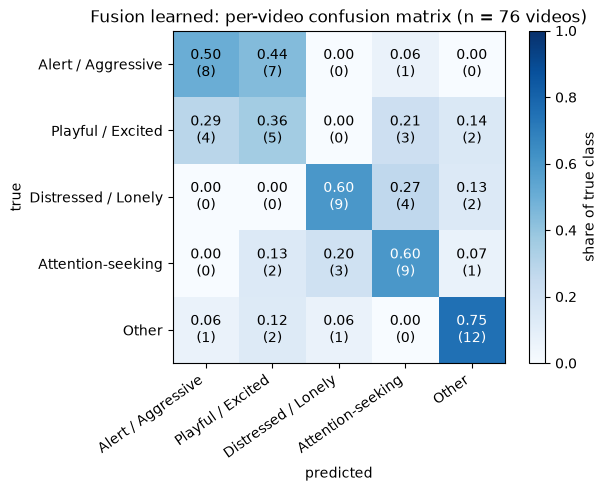

In [13]:
fusion = learned["fusion learned"]
per_video = pd.DataFrame(fusion.oof_probs, columns=CATEGORIES)
per_video["video_id"] = trainval["video_id"].to_numpy()
per_video["category"] = trainval["category"].to_numpy()
video_means = per_video.groupby("video_id").agg(
    {**dict.fromkeys(CATEGORIES, "mean"), "category": "first"}
)

plot_confusion_matrix(
    video_means["category"].tolist(),
    video_means[CATEGORIES].idxmax(axis=1).tolist(),
    CATEGORIES,
    f"Fusion learned: per-video confusion matrix (n = {len(video_means)} videos)",
)
plt.show()

## Fit Fusion Head

Fit the fusion head on all train + val segments with the chosen C and temperature.

In [14]:
fusion = learned["fusion learned"]

# The scene version the cached outputs were made with (written by cache_branch_outputs).
with open(FUSION_INFO_PATH, encoding="utf-8") as info_file:
    scene_schema_id = json.load(info_file)["scene_schema_id"]

# Fit on all train + val segments with the C and temperature chosen out-of-fold.
model = fit_fusion(segments, fusion, scene_schema_id)

print("C:", fusion.C, "| T:", round(fusion.temperature, 3))
coefficients = pd.DataFrame(model.head.weights, index=model.head.classes, columns=FEATURE_NAMES)
print(coefficients.round(2).T.to_string())

C: 1.0 | T: 1.373
                         alert_aggressive  attention_seeking  distressed_lonely  other  playful_excited
audio:alert_aggressive               0.87              -0.34              -0.23  -0.17            -0.13
audio:playful_excited                0.69              -0.18              -0.75  -0.22             0.47
audio:distressed_lonely              0.06              -0.21               0.40  -0.06            -0.19
audio:attention_seeking             -0.48               0.52              -0.31   0.21             0.06
audio:other                         -1.15               0.39               0.44   0.27             0.05
body:alert_aggressive                0.44              -0.38              -0.00  -0.17             0.12
body:playful_excited                -0.05               0.56              -0.11  -0.57             0.18
body:distressed_lonely              -0.01              -0.14              -0.24   0.16             0.23
body:attention_seeking              -0.10     

## Save Fusion Head

Save the head to `models/fusion/` and reload it as a check.

In [15]:
model.save(FUSION_DIR)
reloaded = FusionModel.load(FUSION_DIR)
print("saved:", sorted(path.name for path in FUSION_DIR.iterdir()))
print(
    "C:",
    fusion.C,
    "| T:",
    round(reloaded.head.temperature, 3),
    "| scene schema:",
    reloaded.scene_schema_id[:12],
)

saved: ['fusion_head.npz', 'fusion_info.json']
C: 1.0 | T: 1.373 | scene schema: a34f2d595cac


## Results and decisions

Copied from the saved outputs above (train + val, out-of-fold).

```
train + val: 589 segments, 76 videos

        method  segment_log_loss  segment_macro_f1  video_macro_f1  video_accuracy   C  temperature
     audio raw             1.429             0.475           0.475           0.487 NaN          NaN
      body raw             1.940             0.319           0.308           0.342 NaN          NaN
     scene raw             1.949             0.171           0.155           0.237 NaN          NaN
   average raw             1.398             0.399           0.452           0.461 NaN          NaN
 audio learned             1.310             0.425           0.511           0.526 1.0        1.165
  body learned             1.484             0.333           0.362           0.355 1.0        1.655
 scene learned             1.450             0.291           0.285           0.289 0.1        1.054
fusion learned             1.089             0.556           0.564           0.566 1.0        1.373
```

```
fusion − audio learned, segment log-loss: -0.219 [-0.332, -0.103] | fusion lower in 100% of resamples
```

Saved fusion head:

```
saved: ['fusion_head.npz', 'fusion_info.json']
C: 1.0 | T: 1.373 | scene schema: a34f2d595cac
```